# GraphSAGE

## 1 : Importation of the libraries

In [1]:
# ==========================================================
# Cell 1 : Import Libraries
# ==========================================================

import os
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.data import Data
from torch_geometric.nn import GCNConv

from torch_geometric.nn import (
    GATConv,
    global_mean_pool
)

from torch_geometric.nn import SAGEConv

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import optuna

warnings.filterwarnings("ignore")

# ----------------------------------------------------------
# Reproducibility
# ----------------------------------------------------------

SEED = 82

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ----------------------------------------------------------
# Device
# ----------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("Environment Information")
print("=" * 70)

print(f"PyTorch version       : {torch.__version__}")

try:
    import torch_geometric
    print(f"PyTorch Geometric     : {torch_geometric.__version__}")
except:
    pass

print(f"Optuna version        : {optuna.__version__}")
print(f"Device                : {device}")

if torch.cuda.is_available():
    print(f"GPU                    : {torch.cuda.get_device_name(0)}")

Environment Information
PyTorch version       : 2.13.0+cu130
PyTorch Geometric     : 2.8.0
Optuna version        : 4.9.0
Device                : cuda
GPU                    : NVIDIA RTX A4500


## 2: Importation of the dataset

In [2]:
# ==========================================================
# Cell 2 : Load Cleaned Dataset
# ==========================================================

file_path = "International_Trade_Semiconductor_Cleaned_Data_1995_2024.csv"

df = pd.read_csv(file_path)

# ----------------------------------------------------------
# Basic checks
# ----------------------------------------------------------

required_columns = [
    "year",
    "exporter_code",
    "exporter",
    "importer_code",
    "importer",
    "product_code",
    "product",
    "trade_value",
    "quantity",
    "HS2"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

# Numeric conversion
df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

df["trade_value"] = pd.to_numeric(
    df["trade_value"],
    errors="coerce"
)

df["quantity"] = pd.to_numeric(
    df["quantity"],
    errors="coerce"
)

# Remove invalid observations
df = df.dropna(
    subset=[
        "year",
        "exporter",
        "importer",
        "trade_value"
    ]
).copy()

df = df[
    df["trade_value"] >= 0
].copy()

df["year"] = df["year"].astype(int)

df = df.sort_values(
    [
        "year",
        "exporter",
        "importer"
    ]
).reset_index(drop=True)

print("=" * 70)
print("Cleaned Dataset Loaded Successfully")
print("=" * 70)

print(f"Observations : {len(df):,}")
print(
    f"Period       : "
    f"{df['year'].min()} - {df['year'].max()}"
)

print(
    f"Countries    : "
    f"{len(set(df['exporter']) | set(df['importer']))}"
)

print("\nDataset preview:")

display(df.head())

Cleaned Dataset Loaded Successfully
Observations : 1,218,335
Period       : 1995 - 2024
Countries    : 233

Dataset preview:


,year,exporter_code,exporter,importer_code,importer,product_code,product,trade_value,quantity,HS2
0,1995,4,Afghanistan,208,Denmark,854211,"Electronic circuits: monolithic integrated, di...",2.758,0.002,85
1,1995,4,Afghanistan,246,Finland,854280,Electronic circuits and microassemblies: integ...,9.207,0.207,85
2,1995,8,Albania,12,Algeria,854130,"Electrical apparatus: thyristors, diacs and tr...",2.708,0.033,85
3,1995,8,Albania,380,Italy,854211,"Electronic circuits: monolithic integrated, di...",2.039,0.003,85
4,1995,8,Albania,484,Mexico,854211,"Electronic circuits: monolithic integrated, di...",1.000,0.002,85


## 3: Graph Preprocessing


In [3]:
# ==========================================================
# Cell 3 : Graph Preprocessing
# ==========================================================

print("=" * 70)
print("Graph Preprocessing")
print("=" * 70)

# ----------------------------------------------------------
# Aggregate product-level observations into bilateral flows
# ----------------------------------------------------------

edge_features = (
    df
    .groupby(
        [
            "year",
            "exporter",
            "importer"
        ],
        as_index=False
    )
    .agg(
        total_trade_value=(
            "trade_value",
            "sum"
        ),

        total_quantity=(
            "quantity",
            "sum"
        ),

        traded_products=(
            "product_code",
            "nunique"
        )
    )
)

# ----------------------------------------------------------
# Log-transformed target
# ----------------------------------------------------------

edge_features["log_trade_value"] = np.log1p(
    edge_features["total_trade_value"]
)

# ----------------------------------------------------------
# Global country mapping
# Same node ID across all years
# ----------------------------------------------------------

countries = sorted(
    set(edge_features["exporter"])
    |
    set(edge_features["importer"])
)

country_to_id = {
    country: idx
    for idx, country in enumerate(countries)
}

id_to_country = {
    idx: country
    for country, idx in country_to_id.items()
}

edge_features["source"] = (
    edge_features["exporter"]
    .map(country_to_id)
)

edge_features["target"] = (
    edge_features["importer"]
    .map(country_to_id)
)

print(
    f"Number of countries       : {len(countries)}"
)

print(
    f"Number of bilateral flows : {len(edge_features):,}"
)

print(
    f"Period                    : "
    f"{edge_features['year'].min()} - "
    f"{edge_features['year'].max()}"
)

display(edge_features.head())

Graph Preprocessing
Number of countries       : 233
Number of bilateral flows : 272,196
Period                    : 1995 - 2024


,year,exporter,importer,total_trade_value,total_quantity,traded_products,log_trade_value,source,target
0,1995,Afghanistan,Denmark,2.758,0.002,1,1.323887,0,62
1,1995,Afghanistan,Finland,9.207,0.207,1,2.323074,0,77
2,1995,Albania,Algeria,2.708,0.033,1,1.310493,1,2
3,1995,Albania,Italy,2.039,0.003,1,1.111529,1,105
4,1995,Albania,Mexico,1.000,0.002,1,0.693147,1,132


## 4 : Construction of Yearly Graphs


In [4]:
# ==========================================================
# Cell 4 : Construction of Yearly Graphs
# ==========================================================

print("=" * 70)
print("Construction of Yearly Trade Graphs")
print("=" * 70)

yearly_graph_data = {}

years = sorted(
    edge_features["year"].unique()
)

for year in years:

    yearly = edge_features[
        edge_features["year"] == year
    ].copy()

    edge_index = torch.tensor(
        [
            yearly["source"].values,
            yearly["target"].values
        ],
        dtype=torch.long
    )

    yearly_graph_data[year] = {
        "edge_index": edge_index,
        "dataframe": yearly
    }

    print(
        f"{year} : "
        f"{len(countries)} nodes | "
        f"{edge_index.shape[1]} directed edges"
    )

Construction of Yearly Trade Graphs
1995 : 233 nodes | 4315 directed edges
1996 : 233 nodes | 4699 directed edges
1997 : 233 nodes | 5034 directed edges
1998 : 233 nodes | 5311 directed edges
1999 : 233 nodes | 5736 directed edges
2000 : 233 nodes | 6968 directed edges
2001 : 233 nodes | 7314 directed edges
2002 : 233 nodes | 7476 directed edges
2003 : 233 nodes | 7866 directed edges
2004 : 233 nodes | 8308 directed edges
2005 : 233 nodes | 8477 directed edges
2006 : 233 nodes | 8996 directed edges
2007 : 233 nodes | 9279 directed edges
2008 : 233 nodes | 9500 directed edges
2009 : 233 nodes | 9697 directed edges
2010 : 233 nodes | 9994 directed edges
2011 : 233 nodes | 10132 directed edges
2012 : 233 nodes | 10398 directed edges
2013 : 233 nodes | 10518 directed edges
2014 : 233 nodes | 10551 directed edges
2015 : 233 nodes | 10884 directed edges
2016 : 233 nodes | 11090 directed edges
2017 : 233 nodes | 11179 directed edges
2018 : 233 nodes | 11137 directed edges
2019 : 233 nodes | 1

## 5 : Node Feature Engineering

In [5]:
# ==========================================================
# Cell 5 : Node Feature Engineering
# ==========================================================

print("=" * 70)
print("Node Feature Engineering")
print("=" * 70)

node_features_by_year = {}

NUM_NODES = len(countries)

for year in years:

    yearly = edge_features[
        edge_features["year"] == year
    ]

    features = np.zeros(
        (NUM_NODES, 6),
        dtype=np.float32
    )

    # ------------------------------------------------------
    # Degree features
    # ------------------------------------------------------

    out_degree = (
        yearly
        .groupby("source")["target"]
        .nunique()
    )

    in_degree = (
        yearly
        .groupby("target")["source"]
        .nunique()
    )

    # ------------------------------------------------------
    # Trade aggregates
    # ------------------------------------------------------

    exports = (
        yearly
        .groupby("source")["total_trade_value"]
        .sum()
    )

    imports = (
        yearly
        .groupby("target")["total_trade_value"]
        .sum()
    )

    for node in range(NUM_NODES):

        out_d = out_degree.get(node, 0)

        in_d = in_degree.get(node, 0)

        export_value = exports.get(node, 0)

        import_value = imports.get(node, 0)

        total_trade = (
            export_value
            +
            import_value
        )

        features[node] = [

            out_d,

            in_d,

            out_d + in_d,

            np.log1p(export_value),

            np.log1p(import_value),

            np.log1p(total_trade)

        ]

    node_features_by_year[year] = features

print(
    "Node features created successfully."
)

print(
    "Features:"
)

print(
    [
        "Out Degree",
        "In Degree",
        "Total Degree",
        "Log Exports",
        "Log Imports",
        "Log Total Trade"
    ]
)

Node Feature Engineering
Node features created successfully.
Features:
['Out Degree', 'In Degree', 'Total Degree', 'Log Exports', 'Log Imports', 'Log Total Trade']


## 6 : Edge Feature Engineering

In [6]:
# ==========================================================
# Cell 6 : Edge Feature Engineering
# ==========================================================

print("=" * 70)
print("Edge Feature Engineering")
print("=" * 70)

prediction_samples = {}

for year in years:

    previous_year = year - 1

    if previous_year not in years:
        continue

    current = edge_features[
        edge_features["year"] == year
    ].copy()

    previous = edge_features[
        edge_features["year"] == previous_year
    ][
        [
            "source",
            "target",
            "total_trade_value"
        ]
    ].copy()

    previous = previous.rename(
        columns={
            "total_trade_value":
            "previous_trade_value"
        }
    )

    current = current.merge(
        previous,
        on=["source", "target"],
        how="left"
    )

    current[
        "previous_trade_value"
    ] = current[
        "previous_trade_value"
    ].fillna(0)

    current[
        "log_previous_trade"
    ] = np.log1p(
        current["previous_trade_value"]
    )

    prediction_samples[year] = current

print(
    f"Prediction years : "
    f"{min(prediction_samples.keys())} - "
    f"{max(prediction_samples.keys())}"
)

display(
    prediction_samples[
        min(prediction_samples.keys())
    ].head()
)

Edge Feature Engineering
Prediction years : 1996 - 2024


,year,exporter,importer,total_trade_value,total_quantity,traded_products,log_trade_value,source,target,previous_trade_value,log_previous_trade
0,1996,Afghanistan,Finland,1.477,0.062,1,0.907048,0,77,9.207,2.323074
1,1996,Afghanistan,Slovenia,0.819,0.009,1,0.598287,0,190,0.000,0.000000
2,1996,Afghanistan,Southern African Customs Union (...1999),3.316,0.001,1,1.462329,0,195,0.000,0.000000
3,1996,Afghanistan,Switzerland,43.222,0.007,1,3.789222,0,203,0.000,0.000000
4,1996,Albania,Brazil,2.012,0.003,1,1.102604,1,31,0.000,0.000000


## 7 : PyTorch Geometric Conversion


In [7]:
# ==========================================================
# Cell 7 : PyTorch Geometric Conversion
# ==========================================================

print("=" * 70)
print("PyTorch Geometric Conversion")
print("=" * 70)

pyg_graphs = {}

for target_year in sorted(
    prediction_samples.keys()
):

    input_year = target_year - 1

    # ------------------------------------------------------
    # Node features from t-1
    # ------------------------------------------------------

    x = torch.tensor(
        node_features_by_year[input_year],
        dtype=torch.float
    )

    # ------------------------------------------------------
    # Graph structure from t-1
    # ------------------------------------------------------

    message_edge_index = (
        yearly_graph_data[input_year]
        ["edge_index"]
        .clone()
    )

    # ------------------------------------------------------
    # Prediction edges from year t
    # ------------------------------------------------------

    samples = prediction_samples[
        target_year
    ]

    target_edge_index = torch.tensor(
        [
            samples["source"].values,
            samples["target"].values
        ],
        dtype=torch.long
    )

    # Target = log(1 + trade value)
    y = torch.tensor(
        samples["log_trade_value"].values,
        dtype=torch.float
    )

    # Lagged bilateral flow
    lag_trade = torch.tensor(
        samples[
            "log_previous_trade"
        ].values,
        dtype=torch.float
    ).view(-1, 1)

    pyg_graphs[target_year] = Data(

        x=x,

        edge_index=message_edge_index,

        target_edge_index=target_edge_index,

        y=y,

        lag_trade=lag_trade

    )

print(
    f"{len(pyg_graphs)} temporal PyG graphs created."
)

example_year = sorted(
    pyg_graphs.keys()
)[0]

print(
    f"\nExample ({example_year}):"
)

print(
    pyg_graphs[example_year]
)

PyTorch Geometric Conversion
29 temporal PyG graphs created.

Example (1996):
Data(x=[233, 6], edge_index=[2, 4315], y=[4699], target_edge_index=[2, 4699], lag_trade=[4699, 1])


## 8 : Train / Validation / Test Split

In [8]:
# ==========================================================
# Cell 8 : Train / Validation / Test Split
# ==========================================================

print("=" * 70)
print("Temporal Train / Validation / Test Split")
print("=" * 70)

TRAIN_END = 2018

VAL_START = 2019
VAL_END = 2021

TEST_START = 2022
TEST_END = 2024

train_years = [
    y for y in pyg_graphs
    if y <= TRAIN_END
]

val_years = [
    y for y in pyg_graphs
    if VAL_START <= y <= VAL_END
]

test_years = [
    y for y in pyg_graphs
    if TEST_START <= y <= TEST_END
]

print(
    f"Training   : "
    f"{min(train_years)} - {max(train_years)}"
)

print(
    f"Validation : "
    f"{min(val_years)} - {max(val_years)}"
)

print(
    f"Testing    : "
    f"{min(test_years)} - {max(test_years)}"
)

# ----------------------------------------------------------
# Standardize node features
# Fit ONLY on training years
# ----------------------------------------------------------

scaler = StandardScaler()

training_features = np.vstack(
    [
        node_features_by_year[y - 1]
        for y in train_years
    ]
)

scaler.fit(training_features)

for target_year in pyg_graphs:

    input_year = target_year - 1

    scaled_features = scaler.transform(
        node_features_by_year[input_year]
    )

    pyg_graphs[target_year].x = torch.tensor(
        scaled_features,
        dtype=torch.float
    )

print(
    "\nNode features standardized using "
    "training data only."
)

Temporal Train / Validation / Test Split
Training   : 1996 - 2018
Validation : 2019 - 2021
Testing    : 2022 - 2024

Node features standardized using training data only.


## 9 : GraphSAGE Architecture



In [9]:
# ==========================================================
# Cell 9 : GraphSAGE Architecture
# ==========================================================

class GraphSAGETradePredictor(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_dim,
        embedding_dim,
        num_layers,
        dropout
    ):

        super().__init__()

        self.dropout = dropout

        self.convs = nn.ModuleList()

        # --------------------------------------------------
        # First GraphSAGE layer
        # --------------------------------------------------

        self.convs.append(

            SAGEConv(

                input_dim,

                hidden_dim

            )

        )

        current_dim = hidden_dim

        # --------------------------------------------------
        # Intermediate GraphSAGE layers
        # --------------------------------------------------

        for _ in range(max(0, num_layers - 2)):

            self.convs.append(

                SAGEConv(

                    current_dim,

                    hidden_dim

                )

            )

            current_dim = hidden_dim

        # --------------------------------------------------
        # Final embedding layer
        # --------------------------------------------------

        if num_layers > 1:

            self.convs.append(

                SAGEConv(

                    current_dim,

                    embedding_dim

                )

            )

        else:

            self.convs[0] = SAGEConv(

                input_dim,

                embedding_dim

            )

        # --------------------------------------------------
        # Directed Edge Regression Decoder
        # Same decoder as GCN and GAT
        # --------------------------------------------------

        self.edge_decoder = nn.Sequential(

            nn.Linear(

                embedding_dim * 2 + 1,

                hidden_dim

            ),

            nn.ReLU(),

            nn.Dropout(

                dropout

            ),

            nn.Linear(

                hidden_dim,

                hidden_dim // 2

            ),

            nn.ReLU(),

            nn.Linear(

                hidden_dim // 2,

                1

            )

        )

    # ======================================================
    # Node Encoder
    # ======================================================

    def encode(

        self,

        x,

        edge_index

    ):

        for i, conv in enumerate(

            self.convs

        ):

            x = conv(

                x,

                edge_index

            )

            if i != len(self.convs) - 1:

                x = F.relu(

                    x

                )

                x = F.dropout(

                    x,

                    p=self.dropout,

                    training=self.training

                )

        return x

    # ======================================================
    # Edge Decoder
    # ======================================================

    def decode(

        self,

        z,

        target_edge_index,

        lag_trade

    ):

        source = target_edge_index[0]

        target = target_edge_index[1]

        edge_representation = torch.cat(

            [

                z[source],

                z[target],

                lag_trade

            ],

            dim=1

        )

        prediction = self.edge_decoder(

            edge_representation

        )

        return prediction.squeeze(-1)

    # ======================================================
    # Forward
    # ======================================================

    def forward(

        self,

        data

    ):

        z = self.encode(

            data.x,

            data.edge_index

        )

        prediction = self.decode(

            z,

            data.target_edge_index,

            data.lag_trade

        )

        return prediction


print(
    "GraphSAGETradePredictor architecture defined successfully."
)

GraphSAGETradePredictor architecture defined successfully.


## 10 : Hyperparameter Optimization with Optuna


In [10]:
# ==========================================================
# Cell 10 : Hyperparameter Optimization (GraphSAGE)
# ==========================================================

print("=" * 70)
print("GraphSAGE Hyperparameter Optimization with Optuna")
print("=" * 70)


def train_one_epoch(
    model,
    optimizer,
    years_subset
):

    model.train()

    total_loss = 0

    for year in years_subset:

        data = pyg_graphs[year].to(device)

        optimizer.zero_grad()

        predictions = model(data)

        loss = F.mse_loss(
            predictions,
            data.y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(years_subset)


@torch.no_grad()
def evaluate_log_rmse(
    model,
    years_subset
):

    model.eval()

    predictions_all = []

    targets_all = []

    for year in years_subset:

        data = pyg_graphs[year].to(device)

        predictions = model(data)

        predictions_all.append(
            predictions.cpu().numpy()
        )

        targets_all.append(
            data.y.cpu().numpy()
        )

    predictions_all = np.concatenate(
        predictions_all
    )

    targets_all = np.concatenate(
        targets_all
    )

    rmse = np.sqrt(

        mean_squared_error(

            targets_all,

            predictions_all

        )

    )

    return rmse


# ==========================================================
# Optuna Objective
# ==========================================================

def objective(trial):

    # ------------------------------------------------------
    # Reproducibility
    # ------------------------------------------------------

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

    # ------------------------------------------------------
    # Hyperparameters
    # ------------------------------------------------------

    hidden_dim = trial.suggest_categorical(

        "hidden_dim",

        [32, 64, 128, 256]

    )

    embedding_dim = trial.suggest_categorical(

        "embedding_dim",

        [16, 32, 64, 128]

    )

    num_layers = trial.suggest_int(

        "num_layers",

        2,

        4

    )

    dropout = trial.suggest_float(

        "dropout",

        0.0,

        0.5

    )

    learning_rate = trial.suggest_float(

        "learning_rate",

        1e-4,

        5e-3,

        log=True

    )

    weight_decay = trial.suggest_float(

        "weight_decay",

        1e-7,

        1e-3,

        log=True

    )

    # ------------------------------------------------------
    # Model
    # ------------------------------------------------------

    model = GraphSAGETradePredictor(

        input_dim=
            pyg_graphs[
                train_years[0]
            ].x.shape[1],

        hidden_dim=hidden_dim,

        embedding_dim=embedding_dim,

        num_layers=num_layers,

        dropout=dropout

    ).to(device)

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=learning_rate,

        weight_decay=weight_decay

    )

    # ------------------------------------------------------
    # Optimization
    # ------------------------------------------------------

    best_val_rmse = float("inf")

    patience = 20

    patience_counter = 0

    MAX_OPTUNA_EPOCHS = 150

    for epoch in range(MAX_OPTUNA_EPOCHS):

        train_one_epoch(

            model,

            optimizer,

            train_years

        )

        val_rmse = evaluate_log_rmse(

            model,

            val_years

        )

        trial.report(

            val_rmse,

            epoch

        )

        if trial.should_prune():

            raise optuna.TrialPruned()

        if val_rmse < best_val_rmse:

            best_val_rmse = val_rmse

            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:

            break

    return best_val_rmse


# ==========================================================
# Optuna Study
# ==========================================================

sampler = optuna.samplers.TPESampler(
    seed=SEED
)

pruner = optuna.pruners.MedianPruner(
    n_startup_trials=5
)

study = optuna.create_study(

    direction="minimize",

    sampler=sampler,

    pruner=pruner

)

study.optimize(

    objective,

    n_trials=50,

    show_progress_bar=True

)

best_params = study.best_params

print("\n")

print("=" * 70)
print("BEST HYPERPARAMETERS")
print("=" * 70)

for parameter, value in best_params.items():

    print(

        f"{parameter:<20}: {value}"

    )

print(

    f"\nBest Validation RMSE (log scale): "

    f"{study.best_value:.6f}"

)

[I 2026-07-28 13:27:48,745] A new study created in memory with name: no-name-8e9ff4a0-cd77-47cb-9cc3-c358ee5b5aa5


GraphSAGE Hyperparameter Optimization with Optuna


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-07-28 13:28:02,227] Trial 0 finished with value: 1.3277286291122437 and parameters: {'hidden_dim': 256, 'embedding_dim': 64, 'num_layers': 2, 'dropout': 0.06702500073873224, 'learning_rate': 0.0011088974538468338, 'weight_decay': 2.3547685696275293e-05}. Best is trial 0 with value: 1.3277286291122437.
[I 2026-07-28 13:28:34,325] Trial 1 finished with value: 1.3504172563552856 and parameters: {'hidden_dim': 64, 'embedding_dim': 16, 'num_layers': 4, 'dropout': 0.2940170302841303, 'learning_rate': 0.00013492191947446996, 'weight_decay': 2.379204005336373e-06}. Best is trial 0 with value: 1.3277286291122437.
[I 2026-07-28 13:29:01,429] Trial 2 finished with value: 1.33830726146698 and parameters: {'hidden_dim': 128, 'embedding_dim': 128, 'num_layers': 4, 'dropout': 0.16489436525729928, 'learning_rate': 0.0001463463626318621, 'weight_decay': 5.669954329658413e-07}. Best is trial 0 with value: 1.3277286291122437.
[I 2026-07-28 13:29:17,818] Trial 3 finished with value: 1.326446413993

## 11 : Final Model Training



In [11]:
# ==========================================================
# Cell 11 : Final GraphSAGE Model Training
# ==========================================================

print("=" * 70)
print("Final GraphSAGE Model Training")
print("=" * 70)

# ----------------------------------------------------------
# Reset random seeds before final model training
# ----------------------------------------------------------

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():

    torch.cuda.manual_seed(SEED)

    torch.cuda.manual_seed_all(SEED)

# ----------------------------------------------------------
# Initialize best model
# ----------------------------------------------------------

best_model = GraphSAGETradePredictor(

    input_dim=
        pyg_graphs[
            train_years[0]
        ].x.shape[1],

    hidden_dim=
        best_params["hidden_dim"],

    embedding_dim=
        best_params["embedding_dim"],

    num_layers=
        best_params["num_layers"],

    dropout=
        best_params["dropout"]

).to(device)

optimizer = torch.optim.Adam(

    best_model.parameters(),

    lr=
        best_params["learning_rate"],

    weight_decay=
        best_params["weight_decay"]

)

# ----------------------------------------------------------
# Training configuration
# ----------------------------------------------------------

MAX_EPOCHS = 500

PATIENCE = 50

best_val_rmse = float("inf")

best_model_state = None

patience_counter = 0

train_rmse_history = []

val_rmse_history = []

best_epoch = 0

# ----------------------------------------------------------
# Training
# ----------------------------------------------------------

for epoch in range(

    1,

    MAX_EPOCHS + 1

):

    # ------------------------------------------------------
    # One training epoch
    # ------------------------------------------------------

    train_mse = train_one_epoch(

        best_model,

        optimizer,

        train_years

    )

    train_rmse = np.sqrt(

        train_mse

    )

    # ------------------------------------------------------
    # Validation
    # ------------------------------------------------------

    val_rmse = evaluate_log_rmse(

        best_model,

        val_years

    )

    # ------------------------------------------------------
    # Save learning curves
    # ------------------------------------------------------

    train_rmse_history.append(

        train_rmse

    )

    val_rmse_history.append(

        val_rmse

    )

    # ------------------------------------------------------
    # Early stopping
    # ------------------------------------------------------

    if val_rmse < best_val_rmse:

        best_val_rmse = val_rmse

        best_epoch = epoch

        best_model_state = copy.deepcopy(

            best_model.state_dict()

        )

        patience_counter = 0

    else:

        patience_counter += 1

    # ------------------------------------------------------
    # Display progress
    # ------------------------------------------------------

    if epoch % 25 == 0:

        print(

            f"Epoch {epoch:4d} | "

            f"Train RMSE: "

            f"{train_rmse:.6f} | "

            f"Validation RMSE: "

            f"{val_rmse:.6f}"

        )

    # ------------------------------------------------------
    # Early stopping condition
    # ------------------------------------------------------

    if patience_counter >= PATIENCE:

        print(

            f"\nEarly stopping triggered "

            f"at epoch {epoch}."

        )

        break

# ----------------------------------------------------------
# Restore best model
# ----------------------------------------------------------

best_model.load_state_dict(

    best_model_state

)

print("\n")

print("=" * 70)
print("Training Completed")
print("=" * 70)

print(

    f"Best epoch          : {best_epoch}"

)

print(

    f"Best Validation RMSE: "

    f"{best_val_rmse:.6f}"

)

# ----------------------------------------------------------
# Save best model (optional)
# ----------------------------------------------------------

torch.save(

    best_model.state_dict(),

    "best_graphsage_model.pth"

)

print(

    "\nBest model saved as: best_graphsage_model.pth"

)

Final GraphSAGE Model Training
Epoch   25 | Train RMSE: 1.391739 | Validation RMSE: 1.342862
Epoch   50 | Train RMSE: 1.379166 | Validation RMSE: 1.335585
Epoch   75 | Train RMSE: 1.378898 | Validation RMSE: 1.335725
Epoch  100 | Train RMSE: 1.373484 | Validation RMSE: 1.327575
Epoch  125 | Train RMSE: 1.376690 | Validation RMSE: 1.328091
Epoch  150 | Train RMSE: 1.374548 | Validation RMSE: 1.334764
Epoch  175 | Train RMSE: 1.361436 | Validation RMSE: 1.329044
Epoch  200 | Train RMSE: 1.408701 | Validation RMSE: 1.330236

Early stopping triggered at epoch 205.


Training Completed
Best epoch          : 155
Best Validation RMSE: 1.322766

Best model saved as: best_graphsage_model.pth


## 12 : Performance Evaluation



GraphSAGE Performance Evaluation
Seed =  82


TRAIN / VALIDATION / TEST PERFORMANCE


,Dataset,MSE (Billion USD²),RMSE (Billion USD),MAE (Billion USD),R²
0,Training,0.0803,0.2833,0.0206,0.8021
1,Validation,0.0557,0.2360,0.0162,0.9651
2,Test,0.0811,0.2848,0.0220,0.9639




BEST HYPERPARAMETERS
hidden_dim          : 256
embedding_dim       : 32
num_layers          : 4
dropout             : 0.07952342907799548
learning_rate       : 0.0024181287676187757
weight_decay        : 4.073054868060851e-06
best_epoch          : 155


GLOBAL TEST PERFORMANCE (2022–2024)


,Metric,Value,Unit
0,MSE,0.0811,Billion USD²
1,RMSE,0.2848,Billion USD
2,MAE,0.0220,Billion USD
3,R²,0.9639,Dimensionless




PERFORMANCE BY TEST YEAR


,Year,MSE (Billion USD²),RMSE (Billion USD),MAE (Billion USD),R²
0,2022,0.0667,0.2583,0.0216,0.9726
1,2023,0.0489,0.2210,0.0186,0.9733
2,2024,0.1306,0.3614,0.0260,0.9475


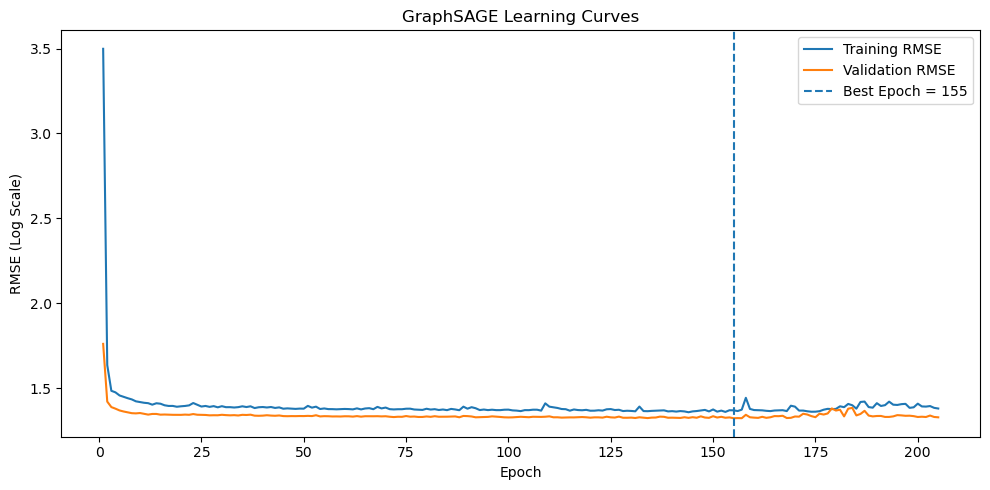

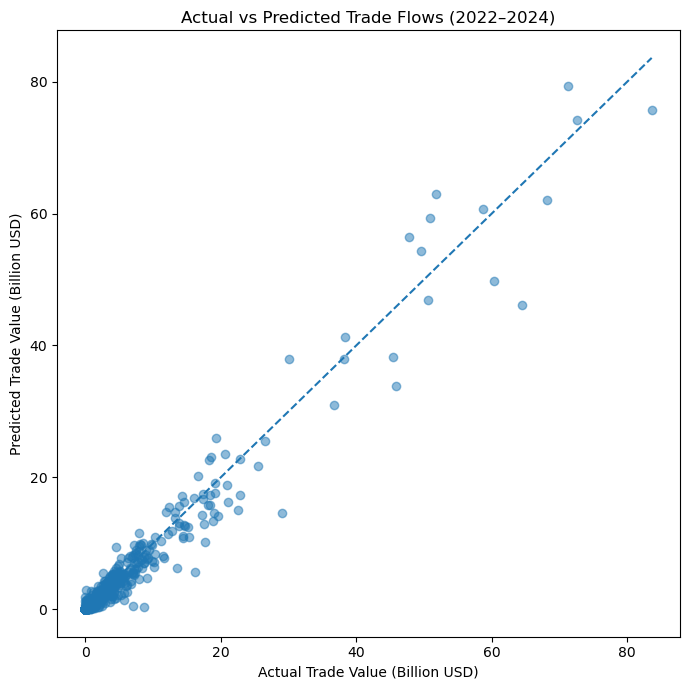

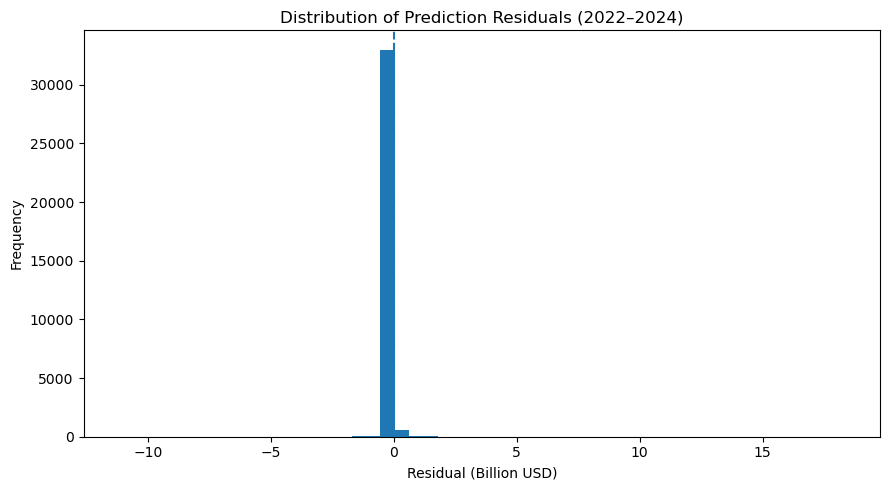



TOP 20 LARGEST ACTUAL TRADE FLOWS (TEST PERIOD 2022–2024)


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2024,China,"China, Hong Kong SAR",83.6043,75.7612,7.8431,9.3812
1,2023,China,"China, Hong Kong SAR",72.5261,74.2531,1.7270,2.3812
2,2022,China,"China, Hong Kong SAR",71.2368,79.3221,8.0853,11.3499
3,2022,Rep. of Korea,China,68.1600,61.9942,6.1659,9.0462
4,2024,Rep. of Korea,China,64.4104,46.1096,18.3008,28.4128
5,2022,"Other Asia, nes",China,60.3728,49.7015,10.6713,17.6757
6,2022,"Other Asia, nes","China, Hong Kong SAR",58.6591,60.7226,2.0636,3.5179
7,2023,"Other Asia, nes","China, Hong Kong SAR",51.7956,62.9434,11.1478,21.5227
8,2023,Rep. of Korea,China,50.8122,59.2646,8.4524,16.6345
9,2024,"Other Asia, nes",China,50.5928,46.8867,3.7061,7.3253




TOP 20 LARGEST PREDICTED TRADE FLOWS (TEST PERIOD 2022–2024)


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2022,China,"China, Hong Kong SAR",71.2368,79.3221,8.0853,11.3499
1,2024,China,"China, Hong Kong SAR",83.6043,75.7612,7.8431,9.3812
2,2023,China,"China, Hong Kong SAR",72.5261,74.2531,1.7270,2.3812
3,2023,"Other Asia, nes","China, Hong Kong SAR",51.7956,62.9434,11.1478,21.5227
4,2022,Rep. of Korea,China,68.1600,61.9942,6.1659,9.0462
5,2022,"Other Asia, nes","China, Hong Kong SAR",58.6591,60.7226,2.0636,3.5179
6,2023,Rep. of Korea,China,50.8122,59.2646,8.4524,16.6345
7,2024,"Other Asia, nes","China, Hong Kong SAR",47.7702,56.4846,8.7143,18.2421
8,2023,"Other Asia, nes",China,49.5887,54.3071,4.7183,9.5149
9,2022,"Other Asia, nes",China,60.3728,49.7015,10.6713,17.6757




SAMPLE TEST PREDICTIONS


,Year,Exporter,Importer,Actual Trade (Billion USD),Predicted Trade (Billion USD),Absolute Error (Billion USD),Relative Error (%)
0,2022,Afghanistan,Canada,0.0000,0.0,0.0000,33.3059
1,2022,Afghanistan,China,0.0000,0.0,0.0000,42.5050
2,2022,Afghanistan,Guatemala,0.0000,0.0,0.0000,525.7796
3,2022,Afghanistan,Ireland,0.0000,0.0,0.0000,419.9879
4,2022,Afghanistan,Japan,0.0001,0.0,0.0000,63.8820
5,2022,Afghanistan,Malaysia,0.0004,0.0,0.0004,98.1854
6,2022,Afghanistan,Poland,0.0000,0.0,0.0000,21.0168
7,2022,Afghanistan,Rep. of Korea,0.0000,0.0,0.0000,2899.9673
8,2022,Afghanistan,Singapore,0.0000,0.0,0.0000,64.6271
9,2022,Afghanistan,Slovakia,0.0000,0.0,0.0000,31.9854


In [12]:
# ==========================================================
# Cell 12 : Performance Evaluation
# ==========================================================

print("=" * 70)
print("GraphSAGE Performance Evaluation")
print("Seed = ",SEED)
print("=" * 70)


@torch.no_grad()
def predict_years(
    model,
    years_subset
):

    model.eval()

    results = []

    for year in years_subset:

        data = pyg_graphs[year].to(
            device
        )

        pred_log = model(
            data
        ).cpu().numpy()

        true_log = (
            data.y
            .cpu()
            .numpy()
        )

        # --------------------------------------------------
        # Back-transform from log1p
        # --------------------------------------------------

        pred_original = np.expm1(
            pred_log
        )

        true_original = np.expm1(
            true_log
        )

        # Negative predictions are not economically valid
        pred_original = np.clip(
            pred_original,
            0,
            None
        )

        samples = prediction_samples[
            year
        ].reset_index(drop=True)

        for i in range(
            len(samples)
        ):

            results.append({

                "Year":
                    year,

                "Exporter":
                    samples.loc[
                        i,
                        "exporter"
                    ],

                "Importer":
                    samples.loc[
                        i,
                        "importer"
                    ],

                "Actual_Trade":
                    true_original[i],

                "Predicted_Trade":
                    pred_original[i]

            })

    return pd.DataFrame(
        results
    )


# ==========================================================
# Generate Train / Validation / Test Predictions
# ==========================================================

train_predictions = predict_years(
    best_model,
    train_years
)

val_predictions = predict_years(
    best_model,
    val_years
)

test_predictions = predict_years(
    best_model,
    test_years
)


# ==========================================================
# Convert BACI Thousand USD -> Billion USD
# ==========================================================

for predictions_df in [
    train_predictions,
    val_predictions,
    test_predictions
]:

    predictions_df[
        "Actual Trade (Billion USD)"
    ] = (
        predictions_df[
            "Actual_Trade"
        ]
        / 1_000_000
    )

    predictions_df[
        "Predicted Trade (Billion USD)"
    ] = (
        predictions_df[
            "Predicted_Trade"
        ]
        / 1_000_000
    )


# ==========================================================
# Function for Performance Metrics
# ==========================================================

def calculate_metrics(
    predictions_df
):

    true_values = predictions_df[
        "Actual_Trade"
    ].values

    predicted_values = predictions_df[
        "Predicted_Trade"
    ].values

    mse_value = mean_squared_error(
        true_values,
        predicted_values
    )

    rmse_value = np.sqrt(
        mse_value
    )

    mae_value = mean_absolute_error(
        true_values,
        predicted_values
    )

    r2_value = r2_score(
        true_values,
        predicted_values
    )

    return {

        "MSE (Billion USD²)":
            mse_value
            / (1_000_000 ** 2),

        "RMSE (Billion USD)":
            rmse_value
            / 1_000_000,

        "MAE (Billion USD)":
            mae_value
            / 1_000_000,

        "R²":
            r2_value

    }


# ==========================================================
# Train / Validation / Test Performance
# ==========================================================

generalization_metrics = pd.DataFrame([

    {
        "Dataset": "Training",
        **calculate_metrics(
            train_predictions
        )
    },

    {
        "Dataset": "Validation",
        **calculate_metrics(
            val_predictions
        )
    },

    {
        "Dataset": "Test",
        **calculate_metrics(
            test_predictions
        )
    }

]).round(4)


print("\n")

print("=" * 70)
print("TRAIN / VALIDATION / TEST PERFORMANCE")
print("=" * 70)

display(
    generalization_metrics
)


# ==========================================================
# Global Test Performance
# ==========================================================

global_test_metrics = calculate_metrics(
    test_predictions
)

performance_metrics = pd.DataFrame({

    "Metric": [
        "MSE",
        "RMSE",
        "MAE",
        "R²"
    ],

    "Value": [

        global_test_metrics[
            "MSE (Billion USD²)"
        ],

        global_test_metrics[
            "RMSE (Billion USD)"
        ],

        global_test_metrics[
            "MAE (Billion USD)"
        ],

        global_test_metrics[
            "R²"
        ]

    ],

    "Unit": [

        "Billion USD²",

        "Billion USD",

        "Billion USD",

        "Dimensionless"

    ]

}).round(4)


# ==========================================================
# Best Hyperparameters
# ==========================================================

print("\n")

print("=" * 70)
print("BEST HYPERPARAMETERS")
print("=" * 70)

for parameter, value in best_params.items():

    print(
        f"{parameter:<20}: {value}"
    )

print(
    f"{'best_epoch':<20}: "
    f"{best_epoch}"
)


# ==========================================================
# Global Test Performance
# ==========================================================

print("\n")

print("=" * 70)
print("GLOBAL TEST PERFORMANCE (2022–2024)")
print("=" * 70)

display(
    performance_metrics
)


# ==========================================================
# Performance by Test Year
# ==========================================================

yearly_metrics = []

for year in test_years:

    yearly_results = test_predictions[
        test_predictions["Year"] == year
    ]

    metrics_year = calculate_metrics(
        yearly_results
    )

    yearly_metrics.append({

        "Year":
            year,

        **metrics_year

    })


yearly_metrics = pd.DataFrame(
    yearly_metrics
).round(4)


print("\n")

print("=" * 70)
print("PERFORMANCE BY TEST YEAR")
print("=" * 70)

display(
    yearly_metrics
)


# ==========================================================
# Learning Curves
# ==========================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    range(
        1,
        len(train_rmse_history) + 1
    ),
    train_rmse_history,
    label="Training RMSE"
)

plt.plot(
    range(
        1,
        len(val_rmse_history) + 1
    ),
    val_rmse_history,
    label="Validation RMSE"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.title(
    "GraphSAGE Learning Curves"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "RMSE (Log Scale)"
)

plt.legend()

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Actual vs Predicted
# IMPORTANT:
# Use the complete 2022–2024 test set
# ==========================================================

y_true_test = test_predictions[
    "Actual Trade (Billion USD)"
].values

y_pred_test = test_predictions[
    "Predicted Trade (Billion USD)"
].values


plt.figure(
    figsize=(7, 7)
)

plt.scatter(
    y_true_test,
    y_pred_test,
    alpha=0.5
)

minimum = min(
    y_true_test.min(),
    y_pred_test.min()
)

maximum = max(
    y_true_test.max(),
    y_pred_test.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title(
    "Actual vs Predicted Trade Flows (2022–2024)"
)

plt.xlabel(
    "Actual Trade Value (Billion USD)"
)

plt.ylabel(
    "Predicted Trade Value (Billion USD)"
)

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Residual Distribution
# ==========================================================

residuals = (
    y_true_test
    -
    y_pred_test
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    residuals,
    bins=50
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title(
    "Distribution of Prediction Residuals (2022–2024)"
)

plt.xlabel(
    "Residual (Billion USD)"
)

plt.ylabel(
    "Frequency"
)

plt.grid(False)

plt.tight_layout()

plt.show()


# ==========================================================
# Prediction Output
# ==========================================================

prediction_output = test_predictions[
    [
        "Year",
        "Exporter",
        "Importer",
        "Actual Trade (Billion USD)",
        "Predicted Trade (Billion USD)"
    ]
].copy()


# ----------------------------------------------------------
# Absolute Error
# ----------------------------------------------------------

prediction_output[
    "Absolute Error (Billion USD)"
] = (

    prediction_output[
        "Actual Trade (Billion USD)"
    ]

    -

    prediction_output[
        "Predicted Trade (Billion USD)"
    ]

).abs()


# ----------------------------------------------------------
# Relative Error (%)
# ----------------------------------------------------------

prediction_output[
    "Relative Error (%)"
] = np.where(

    prediction_output[
        "Actual Trade (Billion USD)"
    ] > 0,

    (
        prediction_output[
            "Absolute Error (Billion USD)"
        ]

        /

        prediction_output[
            "Actual Trade (Billion USD)"
        ]

        * 100
    ),

    np.nan

)


# ----------------------------------------------------------
# Round values
# ----------------------------------------------------------

numeric_columns = [

    "Actual Trade (Billion USD)",

    "Predicted Trade (Billion USD)",

    "Absolute Error (Billion USD)",

    "Relative Error (%)"

]

prediction_output[
    numeric_columns
] = prediction_output[
    numeric_columns
].round(4)


# ==========================================================
# Top 20 Largest Actual Trade Flows
# ==========================================================

top20_actual = (

    prediction_output

    .sort_values(

        by="Actual Trade (Billion USD)",

        ascending=False

    )

    .head(20)

    .reset_index(drop=True)

)


print("\n")

print("=" * 70)

print(
    "TOP 20 LARGEST ACTUAL TRADE FLOWS "
    "(TEST PERIOD 2022–2024)"
)

print("=" * 70)

display(
    top20_actual
)


# ==========================================================
# Top 20 Largest Predicted Trade Flows
# ==========================================================

top20_predicted = (

    prediction_output

    .sort_values(

        by="Predicted Trade (Billion USD)",

        ascending=False

    )

    .head(20)

    .reset_index(drop=True)

)


print("\n")

print("=" * 70)

print(
    "TOP 20 LARGEST PREDICTED TRADE FLOWS "
    "(TEST PERIOD 2022–2024)"
)

print("=" * 70)

display(
    top20_predicted
)


# ==========================================================
# Sample Test Predictions
# ==========================================================

print("\n")

print("=" * 70)
print("SAMPLE TEST PREDICTIONS")
print("=" * 70)

display(
    prediction_output.head(25)
)